<a href="https://colab.research.google.com/github/Nosimon-Nahar/LabReport-3_CSE-418/blob/main/Histogram.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Max |manual - OpenCV| difference: 3


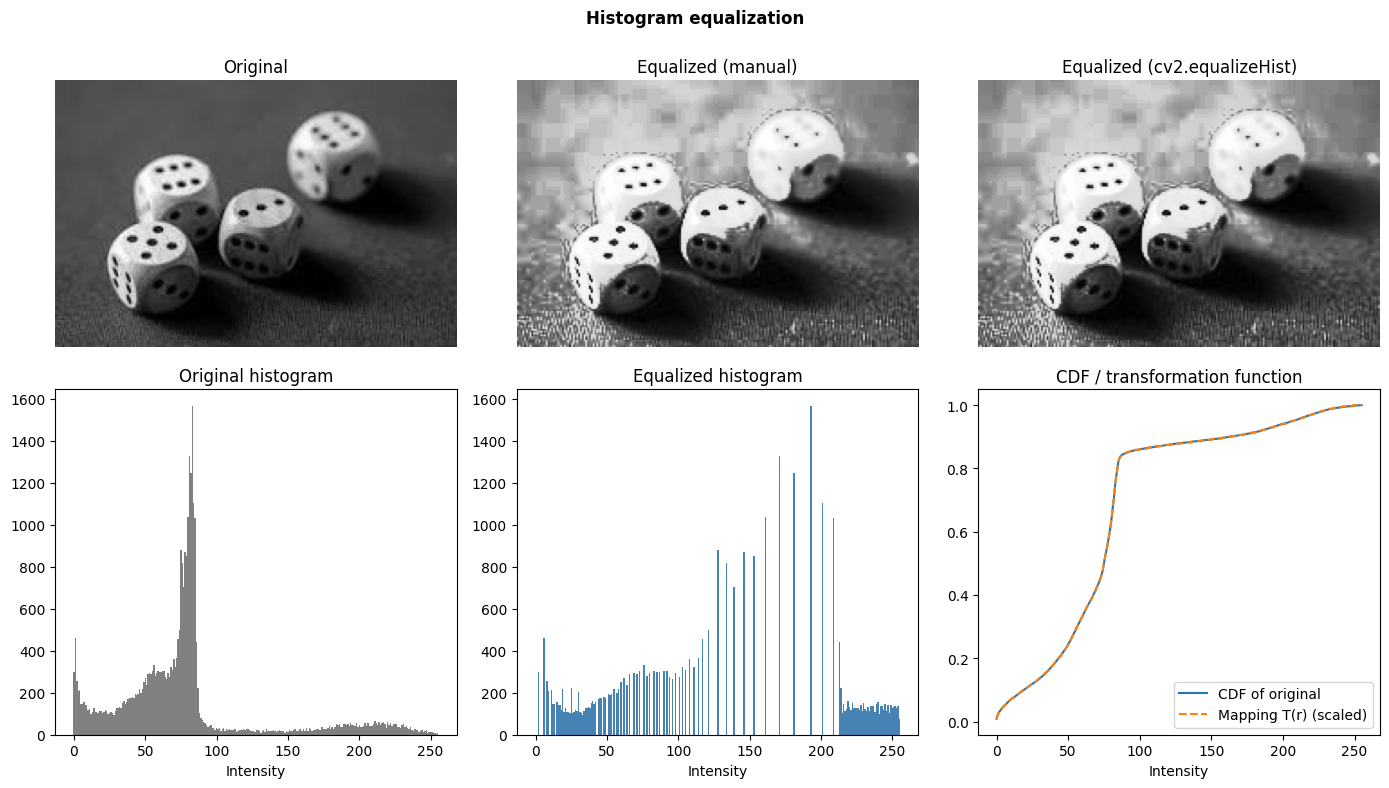

In [1]:
# Histogram equalization and the histogram equalizer
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt

def load_gray(path=None):
  # Load grayscale image; fall back to a low-contrast synthetic image.
    if path:
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            raise ValueError(f"Could not read image: {path}")
        return img
    x, y = np.meshgrid(np.linspace(0, 1, 512), np.linspace(0, 1, 512))
    img = 80 + 60 * x + 30 * np.sin(12 * y) * np.cos(8 * x)
    cv2.circle(img, (256, 256), 100, 170, -1)
    return np.clip(img, 0, 255).astype(np.uint8)

def compute_histogram(img, levels=256):
  # Count pixels at each intensity level.
    hist = np.zeros(levels, dtype=np.int64)
    for v in img.ravel():
        hist[v] += 1
    return hist

def histogram_equalization(img, levels=256):
    """ Histogram equalizer (from scratch):
        pdf(r_k) = n_k / (M*N)
        cdf(r_k) = sum of pdf up to k
        s_k = round((L-1) * cdf(r_k)) """
    hist = compute_histogram(img, levels)
    pdf = hist / img.size
    cdf = np.cumsum(pdf)
    lut = np.round((levels - 1) * cdf).astype(np.uint8)  # transformation T(r)
    eq = lut[img]
    return eq, hist, compute_histogram(eq, levels), cdf, lut

def main():
    img = load_gray("/content/download.jpg")

    eq, h_orig, h_eq, cdf, lut = histogram_equalization(img)
    eq_cv = cv2.equalizeHist(img)  # OpenCV reference
    print("Max |manual - OpenCV| difference:",
          int(np.abs(eq.astype(int) - eq_cv.astype(int)).max()))

    fig, ax = plt.subplots(2, 3, figsize=(14, 8))
    for a, im, t in zip(ax[0], [img, eq, eq_cv],
                        ["Original", "Equalized (manual)", "Equalized (cv2.equalizeHist)"]):
        a.imshow(im, cmap="gray", vmin=0, vmax=255)
        a.set_title(t)
        a.axis("off")
    ax[1, 0].bar(range(256), h_orig, width=1.0, color="gray")
    ax[1, 0].set_title("Original histogram")
    ax[1, 1].bar(range(256), h_eq, width=1.0, color="steelblue")
    ax[1, 1].set_title("Equalized histogram")
    ax[1, 2].plot(cdf, label="CDF of original")
    ax[1, 2].plot(lut / 255.0, "--", label="Mapping T(r) (scaled)")
    ax[1, 2].set_title("CDF / transformation function")
    ax[1, 2].legend()
    for a in ax[1]:
        a.set_xlabel("Intensity")
    fig.suptitle("Histogram equalization", fontweight="bold")
    fig.tight_layout()
    fig.savefig("histogram_result.png", dpi=120)
    plt.show()

if __name__ == "__main__":
    main()